# Titanic Dataset — Data Cleaning & Exploratory Data Analysis

**Inovegen Internship Program 2026 — Week 1 Assignment (AI/ML Task 1)**

## 1. Introduction

This notebook performs a data cleaning and exploratory data analysis (EDA) workflow on the Titanic passenger dataset (`Titanic-Dataset.csv`). The goal is to:

- Inspect the raw dataset and identify data-quality issues.
- Clean the dataset using justified, non-destructive methods.
- Explore relationships between passenger characteristics and survival.
- Present findings through clear visualizations and written insights.

No machine learning model is trained in this notebook — the focus is purely on cleaning and exploratory analysis, as required for Week 1.

**Dataset source:** `Titanic-Dataset.csv` (the classic Kaggle Titanic "train" dataset — 891 passenger records, 12 columns), provided directly for this assignment.

## 2. Import Libraries

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook display / plotting settings
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

## 3. Load Dataset

The dataset is loaded directly from the provided CSV file. We display the first few rows to confirm it loaded correctly.

In [64]:
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 4. Initial Data Inspection

Before cleaning anything, we inspect the dataset's structure, types, and quality so that every cleaning decision made later is based on evidence rather than assumption.

In [65]:
# Shape of the dataset
print("Rows, Columns:", df.shape)

Rows, Columns: (891, 12)


In [66]:
# Column names
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

In [67]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [68]:
# Basic statistical summary (numerical + categorical columns)
df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [69]:
# Missing values per column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct}).sort_values("missing_count", ascending=False)

,missing_count,missing_pct
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


In [70]:
# Duplicate rows
print("Number of fully duplicated rows:", df.duplicated().sum())

Number of fully duplicated rows: 0


### Findings from Initial Inspection

- The dataset has **891 rows and 12 columns**.
- `Age` has **177 missing values (~19.9%)** — a moderate amount that should be imputed rather than dropped.
- `Cabin` has **687 missing values (~77.1%)** — the large majority of records lack this value, so it needs special handling rather than simple imputation.
- `Embarked` has only **2 missing values** — safe to fill with the most common port.
- There are **no fully duplicated rows** in the dataset.
- `Survived`, `Pclass`, `Sex`, and `Embarked` are categorical in nature but currently stored as numbers (`Survived`, `Pclass`) or plain text (`Sex`, `Embarked`) — this doesn't break anything but we will convert them to a `category` dtype for clarity during EDA.
- `Fare` has a minimum value of `0.00`, which looks unusual but is plausible (some passengers, such as crew or staff, historically had recorded fares of 0) — we will not treat this as an error requiring deletion.

## 5. Data Cleaning

Each cleaning decision below follows the same reasoning: **what was found → why it matters → what method was used → why that method fits this data.**

### 5.1 Missing `Age` values (~19.9% missing)

**Problem:** 177 passengers have no recorded age.
**Why it matters:** Age is used in several parts of the EDA (age distribution, age vs. survival), so leaving it missing would exclude ~1 in 5 passengers from that analysis.
**Method chosen:** Fill missing ages with the **median age of that passenger's `Pclass`**, rather than a single overall median.
**Why this is appropriate:** Median age clearly differs by passenger class (checked below), so using a class-specific median is more representative than a single dataset-wide value, while still being robust to outliers (unlike the mean).

In [71]:
# Check whether median age differs meaningfully by passenger class
df.groupby("Pclass")["Age"].median()

,Age
Pclass,
1,37.0
2,29.0
3,24.0


In [72]:
# Fill missing Age with the median age for that passenger's Pclass
df["Age"] = df.groupby("Pclass")["Age"].transform(lambda x: x.fillna(x.median()))

print("Remaining missing values in Age:", df["Age"].isnull().sum())

Remaining missing values in Age: 0


### 5.2 Missing `Cabin` values (~77.1% missing)

**Problem:** Cabin number is missing for the large majority of passengers.
**Why it matters:** With over three-quarters of values missing, filling `Cabin` with a mode or placeholder value would be misleading and would not reflect real information. However, simply dropping the column would throw away the small amount of real signal it does contain (whether a cabin was recorded at all often relates to passenger class and survival).
**Method chosen:** Instead of imputing the missing values, we **derive a new binary feature `Has_Cabin`** (1 if a cabin number was recorded, 0 if missing), and then drop the original high-missingness `Cabin` column.
**Why this is appropriate:** This retains the usable signal in the column (whether a cabin was recorded) without inventing cabin numbers that don't exist in the data.

In [73]:
# Create a binary indicator for whether Cabin information was recorded
df["Has_Cabin"] = df["Cabin"].notnull().astype(int)

# Drop the original Cabin column (too sparse to use directly)
df = df.drop(columns=["Cabin"])

df[["Has_Cabin"]].value_counts()

,count
Has_Cabin,
0,687
1,204


### 5.3 Missing `Embarked` values (2 missing)

**Problem:** Only 2 passengers have no recorded embarkation port.
**Why it matters:** This is a very small number of missing values, so imputation has negligible risk of distorting the analysis.
**Method chosen:** Fill with the **mode** (most frequent port).
**Why this is appropriate:** For a categorical column with very few missing values, using the most common category is a standard, low-risk approach.

In [74]:
print("Most common embarkation port:", df["Embarked"].mode()[0])
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("Remaining missing values in Embarked:", df["Embarked"].isnull().sum())

Most common embarkation port: S
Remaining missing values in Embarked: 0


### 5.4 Duplicate rows

**Problem:** Checked for fully duplicated rows.
**Finding:** None were found (0 duplicate rows), so no rows need to be removed.

In [75]:
print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows after cleaning: 0


### 5.5 Data type corrections

**Problem:** `Survived`, `Pclass`, `Sex`, and `Embarked` are categorical variables but are stored as generic `int64`/`object` types.
**Why it matters:** Treating them explicitly as categories makes grouping and plotting clearer and prevents them from being mistaken for continuous numeric variables.
**Method chosen:** Convert these columns to the pandas `category` dtype. `PassengerId` is also just an identifier, not a numeric feature, so we leave it as-is but exclude it from numerical analysis.

In [76]:
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    df[col] = df[col].astype("category")

df.dtypes

,0
PassengerId,int64
Survived,category
Pclass,category
Name,object
Sex,category
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


### 5.6 Other quality checks

**`Fare` = 0:** A small number of passengers have a fare of 0. This is historically plausible (e.g., crew, employees of the shipping line, or recorded comps) rather than a data-entry error, so these rows are **kept** rather than deleted, consistent with the instruction not to remove data without strong justification.

The dataset contains 15 passengers with a recorded fare of 0. These values were not automatically removed because a zero fare can represent passengers whose fare was covered, recorded differently, or who were traveling under special circumstances. Since removing these observations without additional evidence could introduce bias, they were retained for the analysis.

**No unnecessary changes:** Columns that were already clean (`PassengerId`, `Name`, `SibSp`, `Parch`, `Ticket`, `Fare`) were left untouched, since altering clean data would only introduce risk without benefit.

In [77]:
# The dataset contains 15 passengers with a recorded fare of 0. These values were not automatically removed because a zero fare can represent passengers whose fare was covered, recorded differently, or who were traveling under special circumstances. Since removing these observations without additional evidence could introduce bias, they were retained for the analysis.
print("Passengers with Fare == 0:", (df["Fare"] == 0).sum())

Passengers with Fare == 0: 15


### 5.7 Post-cleaning summary

After cleaning, we confirm that the important issues identified during inspection have been addressed.

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    category
 2   Pclass       891 non-null    category
 3   Name         891 non-null    object  
 4   Sex          891 non-null    category
 5   Age          891 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Embarked     891 non-null    category
 11  Has_Cabin    891 non-null    int64   
dtypes: category(4), float64(2), int64(4), object(2)
memory usage: 59.8+ KB


In [79]:
# Final missing-value check
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


**Result:** `Age` and `Embarked` no longer have missing values. `Cabin`'s usable signal was preserved as `Has_Cabin` rather than being discarded or filled with fabricated values. No rows were dropped, and no clean columns were unnecessarily modified.

## 6. Exploratory Data Analysis

With a clean dataset, we now explore some meaningful questions:

- What proportion of passengers survived overall?
- How does survival differ by gender?
- How does survival differ by passenger class?
- What does the age distribution look like, and does age relate to survival?
- Are there relationships between the numerical variables?

In [80]:
overall_survival_rate = df["Survived"].astype(int).mean()
print(f"Overall survival rate: {overall_survival_rate:.2%}")

Overall survival rate: 38.38%


In [81]:
survival_by_sex = df.groupby("Sex")["Survived"].apply(lambda x: x.astype(int).mean())
survival_by_sex

/tmp/ipykernel_545/3390924207.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival_by_sex = df.groupby("Sex")["Survived"].apply(lambda x: x.astype(int).mean())


,Survived
Sex,
female,0.742038
male,0.188908


In [82]:
survival_by_class = df.groupby("Pclass")["Survived"].apply(lambda x: x.astype(int).mean())
survival_by_class

/tmp/ipykernel_545/4005843972.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival_by_class = df.groupby("Pclass")["Survived"].apply(lambda x: x.astype(int).mean())


,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


In [83]:
df["Age"].describe()

,Age
count,891.000000
mean,29.066409
std,13.244532
min,0.420000
25%,22.000000
50%,26.000000
75%,37.000000
max,80.000000


## 7. Visualizations

### 7.1 Survival Distribution

Shows how many passengers in the dataset survived versus did not survive.

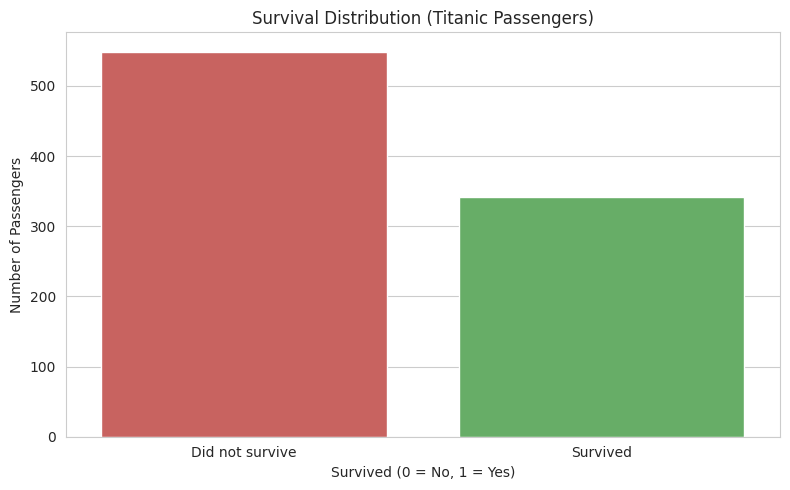

In [84]:
fig, ax = plt.subplots()
sns.countplot(data=df, x="Survived", hue="Survived", palette=["#d9534f", "#5cb85c"], legend=False, ax=ax)
ax.set_title("Survival Distribution (Titanic Passengers)")
ax.set_xlabel("Survived (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Passengers")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Did not survive", "Survived"])
plt.tight_layout()
plt.show()

**Finding:** Out of 891 passengers, only about **38.4%** survived, while roughly **61.6%** did not — survival was the minority outcome overall.

### 7.2 Survival Rate by Gender

Compares the proportion of male and female passengers who survived.

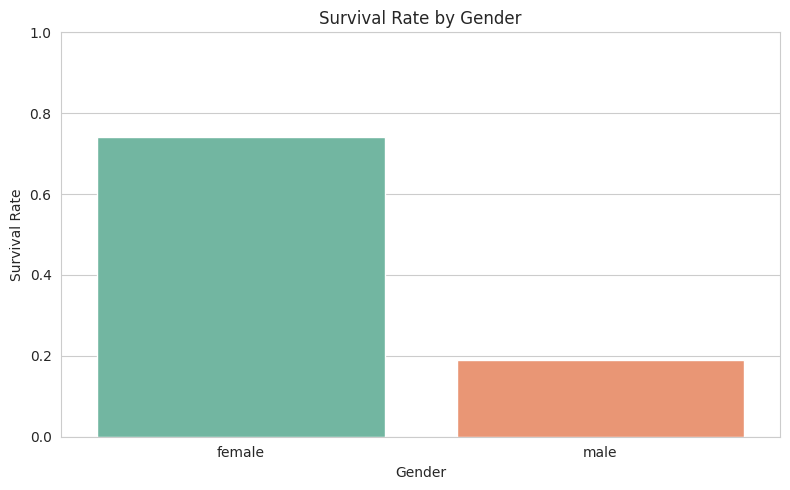

In [85]:
fig, ax = plt.subplots()
sns.barplot(data=df, x="Sex", y=df["Survived"].astype(int), hue="Sex", palette="Set2", legend=False, ax=ax, errorbar=None)
ax.set_title("Survival Rate by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Survival Rate")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Finding:** Female passengers survived at a much higher rate (**~74.2%**) than male passengers (**~18.9%**) — a gap of over 55 percentage points, consistent with a "women first" evacuation pattern.

### 7.3 Survival Rate by Passenger Class

Compares survival rate across the three ticket classes (1st, 2nd, 3rd).

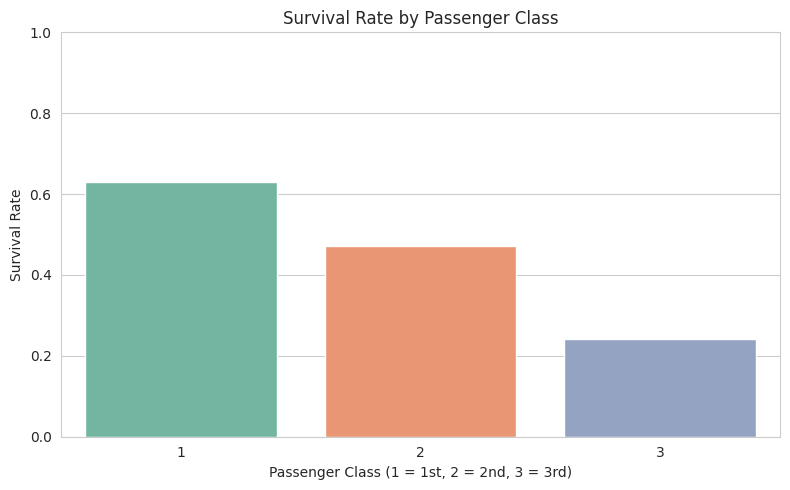

In [86]:
fig, ax = plt.subplots()
sns.barplot(data=df, x="Pclass", y=df["Survived"].astype(int), hue="Pclass", palette="Set2", legend=False, ax=ax, errorbar=None)
ax.set_title("Survival Rate by Passenger Class")
ax.set_xlabel("Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)")
ax.set_ylabel("Survival Rate")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Finding:** Survival rate drops steadily with class — **1st class ~63.0%**, **2nd class ~47.3%**, **3rd class ~24.2%**. Passenger class shows a clear association with survival, likely tied to cabin location and access to lifeboats.

### 7.4 Age Distribution

Shows the overall distribution of passenger ages (after cleaning).

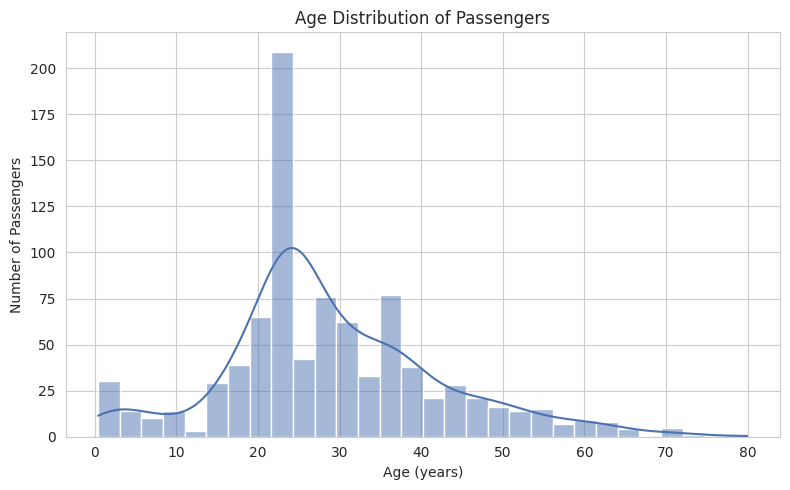

In [87]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="Age", bins=30, kde=True, color="#4c72b0", ax=ax)
ax.set_title("Age Distribution of Passengers")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

**Finding:** The age distribution is right-skewed and concentrated between roughly 20-35 years old, with a median age of 28. There is a smaller secondary cluster of infants/young children, and relatively few passengers above 60.

### 7.5 Fare Distribution and Outliers (Bonus)

A box plot helps identify potential outliers in ticket fares.

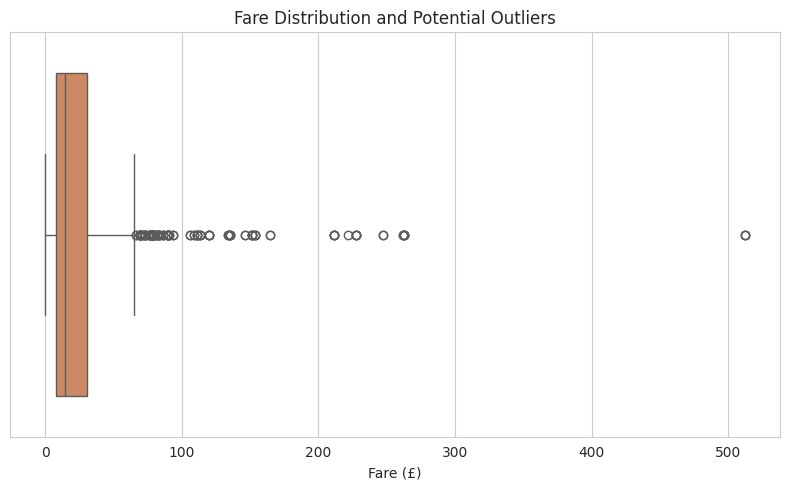

In [88]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="Fare", color="#dd8452", ax=ax)
ax.set_title("Fare Distribution and Potential Outliers")
ax.set_xlabel("Fare (£)")
plt.tight_layout()
plt.show()

In [89]:
q1 = df["Fare"].quantile(0.25)
q3 = df["Fare"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
n_outliers = (df["Fare"] > upper_bound).sum()
print(f"IQR upper bound: {upper_bound:.2f}")
print(f"Number of fares above the upper bound (potential outliers): {n_outliers}")

IQR upper bound: 65.63
Number of fares above the upper bound (potential outliers): 116


**Finding:** Most fares are concentrated below about £31, but a number of passengers paid substantially more (up to £512.33), producing a long right tail of outliers. These are almost certainly legitimate high fares for 1st class or multi-passenger tickets, not data-entry errors, so they are kept in the dataset.

### 7.6 Correlation Heatmap (Bonus)

Shows linear relationships between the numerical variables.

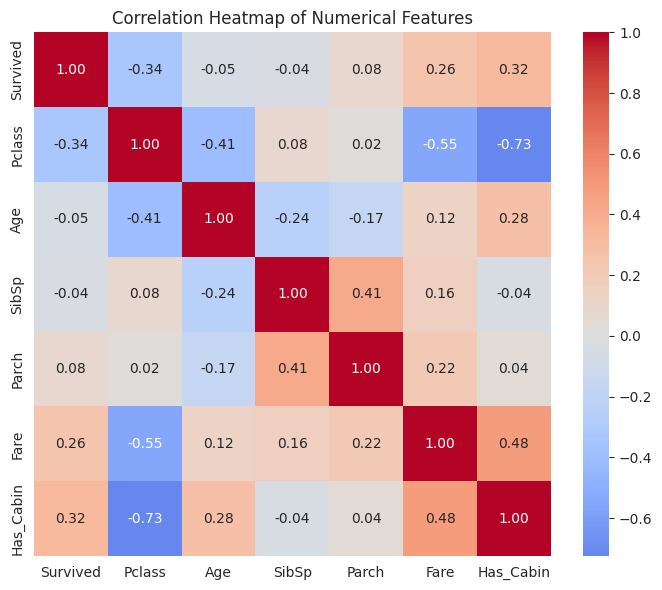

In [90]:
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Has_Cabin"]
corr = df[numeric_cols].astype(float).corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

**Finding:** `Survived` has its strongest correlations with `Pclass` (**-0.34**, higher class number = lower survival), `Fare` (**+0.26**), and `Has_Cabin` (**+0.32**, having a recorded cabin is associated with higher survival) — all modest but consistent with the class-based survival pattern already seen. These are associations, not proof of cause and effect.

### 7.7 Survival by Family Size (Less-Obvious Visualization, Bonus)

Combines `SibSp` (siblings/spouses aboard) and `Parch` (parents/children aboard) into a single family-size measure and checks its relationship with survival.

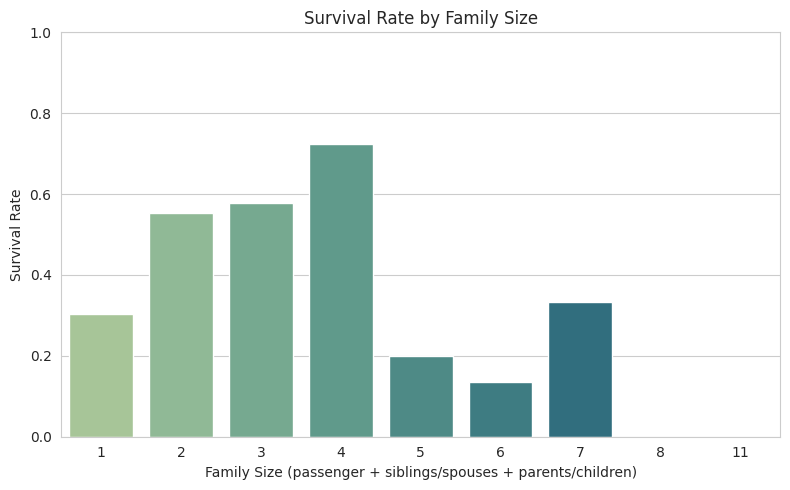

In [91]:
df["Family_Size"] = df["SibSp"] + df["Parch"] + 1  # +1 to include the passenger themself
family_survival = df.groupby("Family_Size")["Survived"].apply(lambda x: x.astype(int).mean())

fig, ax = plt.subplots()
sns.barplot(x=family_survival.index, y=family_survival.values, hue=family_survival.index, palette="crest", legend=False, ax=ax)
ax.set_title("Survival Rate by Family Size")
ax.set_xlabel("Family Size (passenger + siblings/spouses + parents/children)")
ax.set_ylabel("Survival Rate")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Finding:** Passengers traveling with a small family (2-4 members) tended to survive at higher rates than those traveling completely alone (family size 1) or in very large families (7-8+), suggesting both isolation and very large group logistics were associated with lower survival chances.

## 8. Key Insights

1. **Survival was the minority outcome.** Only about **38.4%** of the 891 passengers in this dataset survived, while **61.6%** did not.

2. **Gender was the strongest single factor observed.** Female passengers survived at **~74.2%**, compared to **~18.9%** for male passengers — a difference of roughly **55 percentage points**, far larger than any other single factor examined.

3. **Passenger class was clearly associated with survival.** Survival rate declined steadily from **1st class (~63.0%)** to **2nd class (~47.3%)** to **3rd class (~24.2%)**, and `Pclass` had a negative correlation (-0.34) with survival — consistent with unequal access to lifeboats and cabin locations, though this dataset alone cannot confirm the exact mechanism.

4. **Having a recorded cabin number was associated with higher survival (correlation +0.32).** Since cabin records were far more common in 1st class, this likely reflects the same class-based effect rather than an independent cause.

5. **Family size shows a non-linear relationship with survival.** Passengers traveling alone or in very large families (7+ members) had lower survival rates than those traveling in small families of 2-4, suggesting a balance between having help versus the logistical difficulty of evacuating large groups together.

*Note: all of the above are associations observed in this dataset, not proof of causation.*

## 9. Conclusion

This notebook cleaned and explored the Titanic passenger dataset (891 rows, 12 original columns).

**What was cleaned:**
- Missing `Age` values (~19.9%) were filled using the median age within each passenger class.
- The heavily-missing `Cabin` column (~77.1% missing) was converted into a binary `Has_Cabin` indicator rather than being filled with fabricated values, and the original column was dropped.
- The 2 missing `Embarked` values were filled with the most common port.
- Categorical columns (`Survived`, `Pclass`, `Sex`, `Embarked`) were converted to the `category` dtype for clarity.
- No rows were removed, since there were no duplicate rows and no fare values judged to be genuine errors.

**What the EDA revealed:**
- Only about 38.4% of passengers survived.
- Gender was the strongest observed factor, with a ~55 percentage-point survival gap between women and men.
- Passenger class showed a clear, steady relationship with survival.
- Family size had a non-linear relationship with survival, with small families faring best.

**What was learned:**
Overall, survival on the Titanic was not random — it was strongly associated with who a passenger was (gender), what they could afford (class/fare), and who they were traveling with (family size). These findings are associations drawn from a single historical dataset and should not be interpreted as causal claims.

---
**Dataset source:** `Titanic-Dataset.csv` — the classic Kaggle Titanic training dataset, provided directly for this assignment.